PROTOTIPO A. DETECCION DE EMOCION DE RISA. PIERDES SI TE RIES

El programa muestra contenido gracioso mientras la cámara vigila la cara. Si el modelo detecta que la persona se rie, se pierde. Gana quien aguanta más segundos.

In [30]:
# imports y comprobaciones

import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Carpeta de trabajo:", os.getcwd())
print("TensorFlow", tf.__version__, "| OpenCV", cv2.__version__)

DATOS = "fer2013"   # carpeta con train/ y test/ (junto al notebook)
os.makedirs("img", exist_ok=True)   # carpeta para las imágenes del README

Carpeta de trabajo: /Users/sol/Desktop/VC_practicas-GIT/VC/Practica5_VC
TensorFlow 2.21.0 | OpenCV 4.12.0


In [2]:
# Contar imagenes por clase

for split in ("train", "test"):
    print(split)
    total = 0
    for clase in sorted(os.listdir(os.path.join(DATOS, split))):
        n = len(os.listdir(os.path.join(DATOS, split, clase)))
        total += n
        print(f"  {clase:10s} {n}")
    print(f"  TOTAL      {total}")

train
  angry      3995
  disgust    436
  fear       4097
  happy      7215
  neutral    4965
  sad        4830
  surprise   3171
  TOTAL      28709
test
  angry      958
  disgust    111
  fear       1024
  happy      1774
  neutral    1233
  sad        1247
  surprise   831
  TOTAL      7178


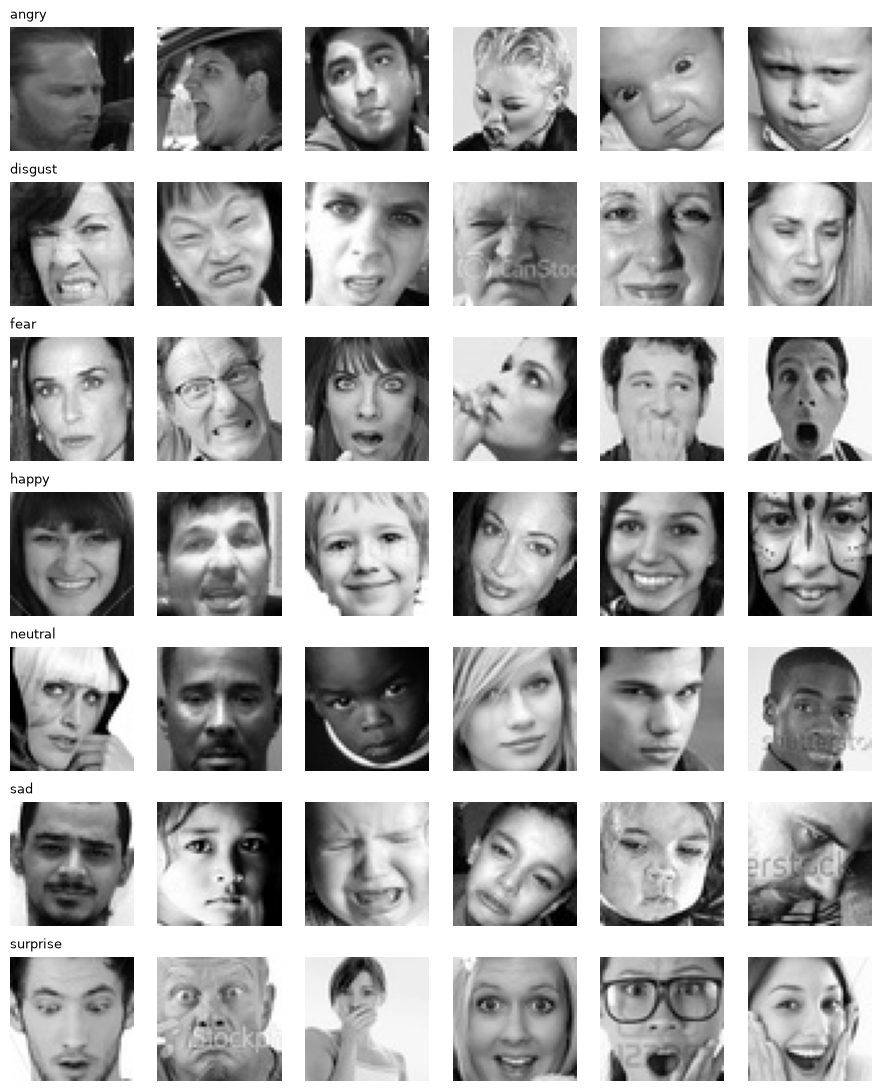

In [5]:
# 6 Ejemplos de cada emoción

import random

clases = sorted(os.listdir(os.path.join(DATOS, "train")))
fig, ejes = plt.subplots(len(clases), 6, figsize=(9, 11))
for i, clase in enumerate(clases):
    carpeta = os.path.join(DATOS, "train", clase)
    nombres = random.sample(os.listdir(carpeta), 6)
    for j, nombre in enumerate(nombres):
        img = cv2.imread(os.path.join(carpeta, nombre), cv2.IMREAD_GRAYSCALE)
        ejes[i, j].imshow(img, cmap="gray")
        ejes[i, j].axis("off")
        if j == 0:
            ejes[i, j].set_title(clase, loc="left", fontsize=9)
plt.tight_layout()
plt.show()

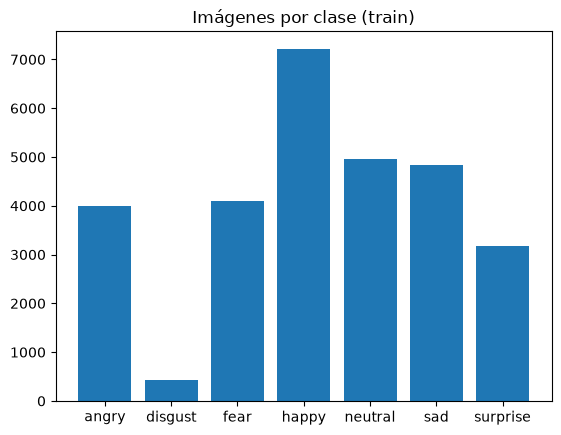

In [6]:
# grafica del numero de imágenes que hay por cada clase  

conteo = [len(os.listdir(os.path.join(DATOS, "train", c))) for c in clases]
plt.bar(clases, conteo)
plt.title("Imágenes por clase (train)")
plt.show()

In [7]:
# Preparamos los datos para el entrenamiento

# Constantes
TAM = 48        # las imágenes de FER2013 son de 48x48 píxeles
BATCH = 64      # cantidad de imágenes ve la red de golpe en cada paso
SEMILLA = 42    # para que el reparto aleatorio sea el mismo cada vez

keras.utils.set_random_seed(SEMILLA)

In [8]:
# Cargamos train, validacion y test

comunes = dict(labels="inferred", label_mode="int", color_mode="grayscale",
               image_size=(TAM, TAM), batch_size=BATCH)

ds_train = keras.utils.image_dataset_from_directory(
    os.path.join(DATOS, "train"), validation_split=0.1, subset="training",
    seed=SEMILLA, **comunes)

ds_val = keras.utils.image_dataset_from_directory(
    os.path.join(DATOS, "train"), validation_split=0.1, subset="validation",
    seed=SEMILLA, **comunes)

ds_test = keras.utils.image_dataset_from_directory(
    os.path.join(DATOS, "test"), shuffle=False, **comunes)

clases = ds_train.class_names
print(clases)

Found 28709 files belonging to 7 classes.
Using 25839 files for training.
Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [9]:
# Observamos que recibe la red 

for imagenes, etiquetas in ds_train.take(1):
    print(imagenes.shape, etiquetas.shape, imagenes.dtype)

    # en este caso recibe 64 imagenes de 48x48 con un canal y 64 etiquetas 

(64, 48, 48, 1) (64,) <dtype: 'float32'>


In [11]:
# Pesos por clase
    # Como disgust tiene muy pocas imágenes, la red podría ignorarlo. Con los pesos, cada error en una clase rara cuenta más en la función de pérdida.
from sklearn.utils.class_weight import compute_class_weight

n_train = [len(os.listdir(os.path.join(DATOS, "train", c))) for c in clases]
y_todas = np.repeat(np.arange(len(clases)), n_train)

pesos = compute_class_weight("balanced", classes=np.arange(len(clases)), y=y_todas)
pesos = np.sqrt(pesos)    # suavizado
class_weight = {i: float(w) for i, w in enumerate(pesos)}
print({clases[i]: round(w, 2) for i, w in class_weight.items()})

{'angry': 1.01, 'disgust': 3.07, 'fear': 1.0, 'happy': 0.75, 'neutral': 0.91, 'sad': 0.92, 'surprise': 1.14}


In [12]:
# Para que la carga de datos no frene el entrenamiento

ds_train = ds_train.prefetch(tf.data.AUTOTUNE)
ds_val = ds_val.prefetch(tf.data.AUTOTUNE)

In [16]:
# Construimos el modelo

FILTROS = 32   # filtros del primer bloque (se duplican en cada bloque)

def bloque(x, filtros):
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)
    return x

entrada = keras.Input((TAM, TAM, 1))
x = layers.Rescaling(1.0 / 255)(entrada)

# Aumento de datos: solo actúa al entrenar, no al predecir
x = layers.RandomFlip("horizontal")(x)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomZoom(0.1)(x)
x = layers.RandomTranslation(0.08, 0.08)(x)

for filtros in (FILTROS, 2 * FILTROS, 4 * FILTROS, 8 * FILTROS):
    x = bloque(x, filtros)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.5)(x)
salida = layers.Dense(len(clases), activation="softmax")(x)

modelo = keras.Model(entrada, salida, name="cnn_emociones")
modelo.summary()

Model: "cnn_emociones"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 48, 48, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 12, 12, 64)     │             

 Total params: 1,242,919 (4.74 MB)

 Trainable params: 1,240,487 (4.73 MB)

 Non-trainable params: 2,432 (9.50 KB)

In [17]:
# Compilamos 

modelo.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [18]:
# Entrenamiento
import time

EPOCAS = 30   

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    keras.callbacks.ModelCheckpoint("emociones_mejor.keras", monitor="val_loss", save_best_only=True),
]

t0 = time.time()
historial = modelo.fit(ds_train, validation_data=ds_val, epochs=EPOCAS,
                       class_weight=class_weight, callbacks=callbacks)
t_entreno = time.time() - t0
print(f"Entrenamiento: {len(historial.history['loss'])} épocas en {t_entreno / 60:.1f} min")

Epoch 1/30
404/404 ━━━━━━━━━━━━━━━━━━━━ 91s 218ms/step - accuracy: 0.2093 - loss: 2.0010 - val_accuracy: 0.2108 - val_loss: 1.9217 - learning_rate: 0.0010
Epoch 2/30
404/404 ━━━━━━━━━━━━━━━━━━━━ 85s 211ms/step - accuracy: 0.2611 - loss: 1.8107 - val_accuracy: 0.2286 - val_loss: 1.8630 - learning_rate: 0.0010
Epoch 3/30
404/404 ━━━━━━━━━━━━━━━━━━━━ 83s 206ms/step - accuracy: 0.3371 - loss: 1.6735 - val_accuracy: 0.3718 - val_loss: 1.6332 - learning_rate: 0.0010
Epoch 4/30
404/404 ━━━━━━━━━━━━━━━━━━━━ 85s 210ms/step - accuracy: 0.4095 - loss: 1.5240 - val_accuracy: 0.3289 - val_loss: 1.6786 - learning_rate: 0.0010
Epoch 5/30
404/404 ━━━━━━━━━━━━━━━━━━━━ 87s 214ms/step - accuracy: 0.4467 - loss: 1.4298 - val_accuracy: 0.4017 - val_loss: 1.5715 - learning_rate: 0.0010
Epoch 6/30
404/404 ━━━━━━━━━━━━━━━━━━━━ 84s 208ms/step - accuracy: 0.4765 - loss: 1.3662 - val_accuracy: 0.4704 - val_loss: 1.3799 - learning_rate: 0.0010
Epoch 7/30
404/404 ━━━━━━━━━━━━━━━━━━━━ 86s 214ms/step - accuracy: 0.4

In [22]:
import json

if not os.path.exists("emociones_30ep.keras"):
    modelo.save("emociones_30ep.keras")
    with open("historial_fase1.json", "w") as f:
        json.dump({k: [float(v) for v in vs] for k, vs in historial.history.items()}, f)
    print("Copia de seguridad de la fase 1 guardada.")
else:
    print("La copia de la fase 1 ya existe: no se sobrescribe.")

La copia de la fase 1 ya existe: no se sobrescribe.


Entrenamiento con más epocas 

In [21]:
import time

modelo = keras.models.load_model("emociones_30ep.keras")

callbacks2 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    keras.callbacks.ModelCheckpoint("emociones_mejor_fase2.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.CSVLogger("historial_fase2.csv"),
]
t0 = time.time()
historial_2 = modelo.fit(ds_train, validation_data=ds_val, initial_epoch=30, epochs=70,
                         class_weight=class_weight, callbacks=callbacks2)
t_fase2 = time.time() - t0
print(f"Fase 2: {len(historial_2.history['loss'])} épocas en {t_fase2 / 60:.1f} min")

Epoch 31/70
404/404 ━━━━━━━━━━━━━━━━━━━━ 83s 200ms/step - accuracy: 0.6169 - loss: 0.9966 - val_accuracy: 0.5927 - val_loss: 1.0738 - learning_rate: 1.2500e-04
Epoch 32/70
404/404 ━━━━━━━━━━━━━━━━━━━━ 82s 203ms/step - accuracy: 0.6147 - loss: 0.9978 - val_accuracy: 0.6024 - val_loss: 1.0444 - learning_rate: 1.2500e-04
Epoch 33/70
404/404 ━━━━━━━━━━━━━━━━━━━━ 83s 205ms/step - accuracy: 0.6143 - loss: 0.9987 - val_accuracy: 0.5983 - val_loss: 1.0550 - learning_rate: 1.2500e-04
Epoch 34/70
404/404 ━━━━━━━━━━━━━━━━━━━━ 83s 206ms/step - accuracy: 0.6172 - loss: 0.9916 - val_accuracy: 0.5920 - val_loss: 1.0758 - learning_rate: 1.2500e-04
Epoch 35/70
404/404 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.6189 - loss: 0.9878
Epoch 35: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
404/404 ━━━━━━━━━━━━━━━━━━━━ 84s 207ms/step - accuracy: 0.6189 - loss: 0.9878 - val_accuracy: 0.5934 - val_loss: 1.0762 - learning_rate: 1.2500e-04
Epoch 36/70
404/404 ━━━━━━━━━━━━━━━━━━━━ 84s 20

In [26]:
# Guardamos el modelo final (epoca 45)

modelo = keras.models.load_model("emociones_mejor_fase2.keras")
modelo.save("emociones.keras")
print("Modelo final guardado: época 45 de 53")

Modelo final guardado: época 45 de 53


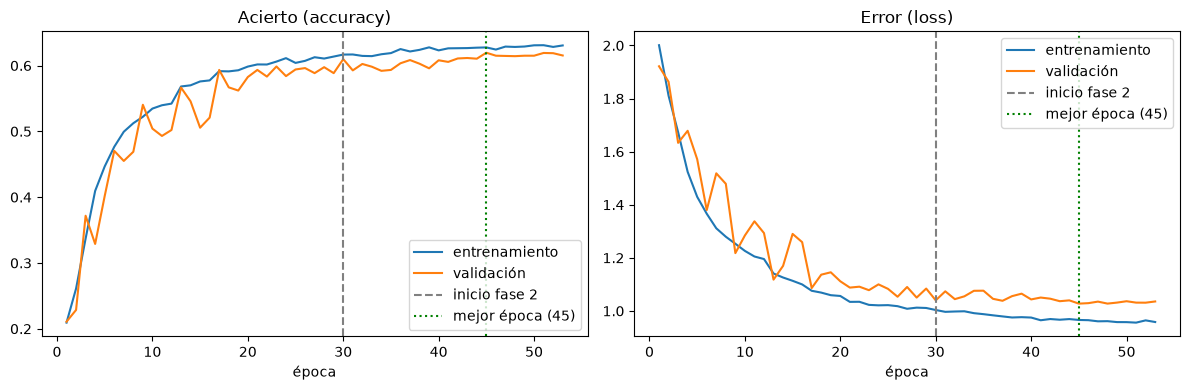

Mejor época: 45 (val_loss=1.0275, val_accuracy=0.6195)
Épocas totales: 53


In [27]:
# grafica de las dos fases

import json

with open("historial_fase1.json") as f:
    h1 = json.load(f)
h2 = historial_2.history
h = {k: h1[k] + h2[k] for k in ("accuracy", "val_accuracy", "loss", "val_loss")}

epocas = range(1, len(h["loss"]) + 1)
mejor = int(np.argmin(h["val_loss"])) + 1

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(epocas, h["accuracy"], label="entrenamiento")
ejes[0].plot(epocas, h["val_accuracy"], label="validación")
ejes[0].axvline(30, color="gray", linestyle="--", label="inicio fase 2")
ejes[0].axvline(mejor, color="green", linestyle=":", label=f"mejor época ({mejor})")
ejes[0].set_title("Acierto (accuracy)")
ejes[0].set_xlabel("época")
ejes[0].legend()

ejes[1].plot(epocas, h["loss"], label="entrenamiento")
ejes[1].plot(epocas, h["val_loss"], label="validación")
ejes[1].axvline(30, color="gray", linestyle="--", label="inicio fase 2")
ejes[1].axvline(mejor, color="green", linestyle=":", label=f"mejor época ({mejor})")
ejes[1].set_title("Error (loss)")
ejes[1].set_xlabel("época")
ejes[1].legend()

plt.tight_layout()
plt.savefig("img/p5_curvas_entrenamiento.png", dpi=150)
plt.show()

print(f"Mejor época: {mejor} (val_loss={h['val_loss'][mejor - 1]:.4f}, val_accuracy={h['val_accuracy'][mejor - 1]:.4f})")
print(f"Épocas totales: {len(h['loss'])}")

In [28]:
perdida_test, acierto_test = modelo.evaluate(ds_test)
print(f"Test: acierto = {acierto_test:.3f} | error = {perdida_test:.3f}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.6216 - loss: 1.0187
Test: acierto = 0.622 | error = 1.019


113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step
              precision    recall  f1-score   support

       angry      0.503     0.596     0.545       958
     disgust      0.500     0.541     0.519       111
        fear      0.495     0.332     0.397      1024
       happy      0.883     0.814     0.847      1774
     neutral      0.524     0.692     0.596      1233
         sad      0.527     0.445     0.483      1247
    surprise      0.696     0.769     0.731       831

    accuracy                          0.622      7178
   macro avg      0.590     0.598     0.588      7178
weighted avg      0.626     0.622     0.618      7178



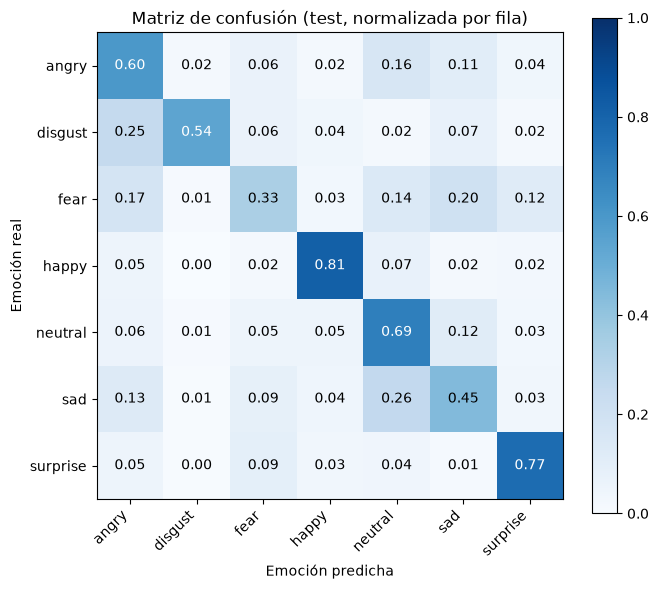

In [29]:
from sklearn.metrics import confusion_matrix, classification_report

y_real = np.concatenate([y.numpy() for _, y in ds_test])
y_prob = modelo.predict(ds_test)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_real, y_pred, target_names=clases, digits=3))

matriz = confusion_matrix(y_real, y_pred)
matriz_pct = matriz / matriz.sum(axis=1, keepdims=True)

fig, eje = plt.subplots(figsize=(7, 6))
im = eje.imshow(matriz_pct, cmap="Blues", vmin=0, vmax=1)
eje.set_xticks(range(len(clases)), clases, rotation=45, ha="right")
eje.set_yticks(range(len(clases)), clases)
eje.set_xlabel("Emoción predicha")
eje.set_ylabel("Emoción real")
eje.set_title("Matriz de confusión (test, normalizada por fila)")
for i in range(len(clases)):
    for j in range(len(clases)):
        eje.text(j, i, f"{matriz_pct[i, j]:.2f}", ha="center", va="center",
                 color="white" if matriz_pct[i, j] > 0.5 else "black")
fig.colorbar(im)
plt.tight_layout()
plt.savefig("img/p5_matriz_confusion.png", dpi=150)
plt.show()

In [32]:
import json

informe = classification_report(y_real, y_pred, target_names=clases, output_dict=True)
resultados = {
    "parametros": int(modelo.count_params()),
    "epocas_totales": 53,
    "mejor_epoca": 45,
    "minutos_fase1": round(t_entreno / 60, 1),
    "minutos_fase2": round(t_fase2 / 60, 1),
    "val_accuracy": 0.6195,
    "test_accuracy": round(float(acierto_test), 4),
    "test_loss": round(float(perdida_test), 4),
    "informe_por_clase": informe,
}
with open("resultados_entrenamiento.json", "w") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)
print("Guardado resultados_entrenamiento.json")

Guardado resultados_entrenamiento.json
